In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import numpy as np

from graphviz import Digraph


In [ ]:
# Create a new directed graph
dot = Digraph('G', format='png')

# Set graph attributes
dot.attr(rankdir='LR', splines='line', fontname='Linux Libertine', dpi='300')
dot.attr('node', fixedsize='true', label='', fontname='Linux Libertine')

# Input layer (cluster_0)
with dot.subgraph(name='cluster_0') as c:
    c.attr(color='white', label='Layer 1 (Input Layer)', fontname='Linux Libertine')
    c.attr('node', style='solid', color='dodgerblue', shape='circle', fontname='Linux Libertine')
    c.node('x1')
    c.node('x2')
    c.node('x3')

# Hidden layer (cluster_1)
with dot.subgraph(name='cluster_1') as c:
    c.attr(color='white', label='Layer 2 (Hidden Layer)', fontname='Linux Libertine')
    c.attr('node', style='solid', color='tomato', shape='circle', fontname='Linux Libertine')
    c.node('h11')
    c.node('h12')
    c.node('h13')

# Output layer (cluster_2)
with dot.subgraph(name='cluster_2') as c:
    c.attr(color='white', label='Layer 3 (Output Layer)', fontname='Linux Libertine')
    c.attr('node', style='solid', color='mediumseagreen', shape='circle', fontname='Linux Libertine')
    c.node('O')

# Add edges from input layer to hidden layer
for input_node in ['x1', 'x2', 'x3']:
    for hidden_node in ['h11', 'h12', 'h13']:
        dot.edge(input_node, hidden_node, fontname='Linux Libertine')

# Add edges from hidden layer to output layer
for hidden_node in ['h11', 'h12', 'h13']:
    dot.edge(hidden_node, 'O', fontname='Linux Libertine')

# Save and render the graph 
dot.render('mlp_visualization', view=True)

,Sector,Emissions (%)
0,Transportation,28.4
1,Electric power,24.9
2,Industry,22.9
3,Agriculture,10.0
4,Commercial,7.3
5,Residential,6.2
6,U.S. Territories,0.4


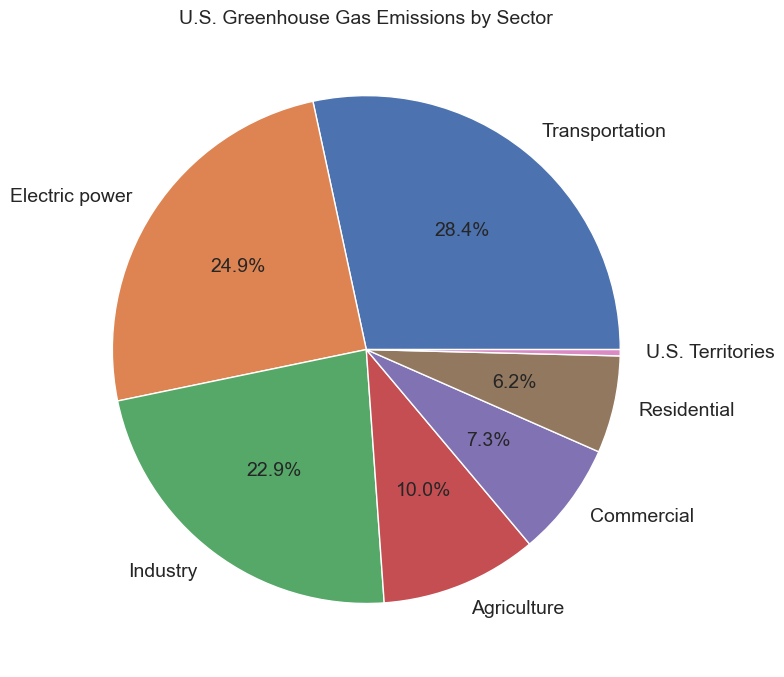

In [ ]:
# https://www.statista.com/statistics/1200954/ghg-emissions-breakdown-by-sector-us/ 

stat_df = pd.DataFrame({
    "Sector": [
        "Transportation",
        "Electric power",
        "Industry",
        "Agriculture",
        "Commercial",
        "Residential",
        "U.S. Territories"
    ],
    "Emissions (%)": [
        28.4,
        24.9,
        22.9,
        10.0,
        7.3,
        6.2,
        0.4
    ]
})

display(stat_df)

# Only allow labels for percentages > 1%
def autopct_filter(pct):
    return f"{pct:.1f}%" if pct > 1 else ""

# Pie chart
plt.figure(figsize=(8, 8))
wedges, texts, autotexts = plt.pie(
    stat_df["Emissions (%)"],
    labels=stat_df["Sector"],
    autopct=autopct_filter,
    textprops={"fontsize": 14}
)

# Set font size for percentage labels
for autotext in autotexts:
    autotext.set_fontsize(14)

plt.title("U.S. Greenhouse Gas Emissions by Sector", fontsize=14)
plt.tight_layout()
plt.show()

In [2]:
# https://www.epa.gov/power-sector/power-sector-evolution
# figure 1

so2_df = pd.read_excel("figure-1-emissions-and-generation-data.xlsx", sheet_name="SO2 Emission Trends", header=2)
nox_df = pd.read_excel("figure-1-emissions-and-generation-data.xlsx", sheet_name="NOx Emission Trends", header=2)
co2_df = pd.read_excel("figure-1-emissions-and-generation-data.xlsx", sheet_name="CO2 Emission Trends", header=2)
gen_df = pd.read_excel("figure-1-emissions-and-generation-data.xlsx", sheet_name="Generation Trend", header=2)

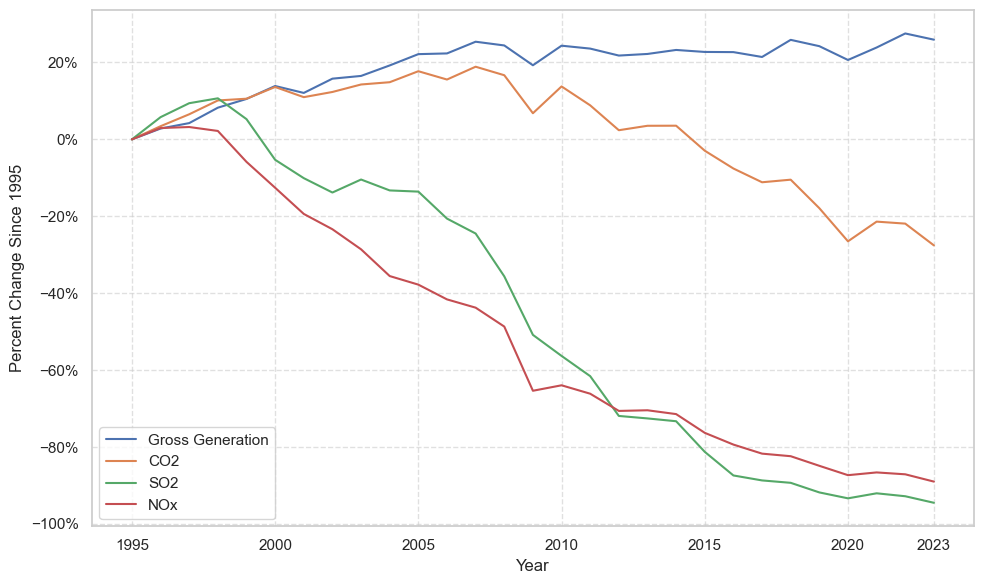

In [ ]:
# Read each sheet, keeping only Year + Percent Change Since 1995
so2_df = pd.read_excel(
    "figure-1-emissions-and-generation-data.xlsx",
    sheet_name="SO2 Emission Trends",
    header=2,
    usecols=["Year", "Percent Change Since 1995"]
).rename(columns={"Percent Change Since 1995": "SO2 % Change"})

so2_df = so2_df.head(29) 
so2_df.loc[0, "SO2 % Change"] = 0

nox_df = pd.read_excel(
    "figure-1-emissions-and-generation-data.xlsx",
    sheet_name="NOx Emission Trends",
    header=2,
    usecols=["Year", "Percent Change Since 1995"]
).rename(columns={"Percent Change Since 1995": "NOx % Change"})

nox_df = nox_df.head(29)
nox_df.loc[0, "NOx % Change"] = 0

co2_df = pd.read_excel(
    "figure-1-emissions-and-generation-data.xlsx",
    sheet_name="CO2 Emission Trends",
    header=2,
    usecols=["Year", "Percent Change Since 1995"]
).rename(columns={"Percent Change Since 1995": "CO2 % Change"})

co2_df = co2_df.head(29)
co2_df.loc[0, "CO2 % Change"] = 0

gen_df = pd.read_excel(
    "figure-1-emissions-and-generation-data.xlsx",
    sheet_name="Generation Trend",
    header=2,
    usecols=["Year", "Percent Change Since 1995"]
).rename(columns={"Percent Change Since 1995": "Generation % Change"})

gen_df = gen_df.head(29)
gen_df.loc[0, "Generation % Change"] = 0

# Merge all dfs on Year
merged_df = so2_df.merge(nox_df, on="Year") \
                  .merge(co2_df, on="Year") \
                  .merge(gen_df, on="Year")

# Create 5-year spaced ticks, plus 2023
year_ticks = list(range(int(merged_df["Year"].min()),
                        int(merged_df["Year"].max()) + 1, 5))
if 2023 not in year_ticks:
    year_ticks.append(2023)
year_ticks = sorted(year_ticks)

plt.figure(figsize=(10, 6))

plt.plot(merged_df["Year"], merged_df["Generation % Change"], label="Gross Generation")
plt.plot(merged_df["Year"], merged_df["CO2 % Change"], label="CO2")
plt.plot(merged_df["Year"], merged_df["SO2 % Change"], label="SO2")
plt.plot(merged_df["Year"], merged_df["NOx % Change"], label="NOx")


#plt.title("Percent Change Since 1995: Emissions & Generation", fontsize=14)
plt.xlabel("Year")
plt.ylabel("Percent Change Since 1995")
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

# Custom ticks
plt.xticks(year_ticks)

plt.tight_layout()
plt.show()
